# 05 — Performance des campagnes et simulation du ROI

**Projet :** Segmentation et score d'appétence d'une base clients retail
**Auteure :** Danielle OUATTARA

**Objectif :** mesurer ce qu'ont rapporté les campagnes passées, puis chiffrer le gain d'un envoi ciblé par rapport à un envoi à toute la base.

| Étape | Contenu |
|---|---|
| 1 | Import et hypothèses économiques |
| 2 | Performance des six campagnes, globalement et par segment |
| 3 | Score « hors échantillon », pour une simulation honnête |
| 4 | Simulation : toute la base contre ciblage par décile |
| 5 | Ciblage par segment |
| 6 | Analyse de sensibilité |
| 7 | Export pour le dashboard |

## 1. Import et hypothèses économiques

In [1]:
import pandas as pd                                          # manipulation de tableaux
import numpy as np                                           # calculs numériques
import matplotlib.pyplot as plt                              # graphiques
from sklearn.model_selection import cross_val_predict, StratifiedKFold   # score hors échantillon
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

pd.set_option("display.max_columns", None)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
COULEUR = "#1F4E79"

df = pd.read_csv("../outputs/clients_scores.csv")             # base scorée par le notebook 04
print(df.shape)                                               # on attend 2 228 lignes

(2228, 55)


In [2]:
COUT_CONTACT = 3                                              # coût d'un contact (colonne Z_CostContact du jeu de données)
REVENU_REPONSE = 11                                           # revenu d'une réponse positive (colonne Z_Revenue)
seuil = COUT_CONTACT / REVENU_REPONSE                         # taux de réponse minimum pour qu'une campagne soit rentable
print(f"Seuil de rentabilité : {seuil:.1%} de taux de réponse")

Seuil de rentabilité : 27.3% de taux de réponse


Avec ces hypothèses, une campagne n'est rentable que si **plus de 27 % des clients contactés répondent**. C'est le chiffre clé de toute la simulation : il suffit de le comparer aux taux de réponse observés.

## 2. Performance des six campagnes

In [3]:
campagnes = {"AcceptedCmp1": "Campagne 1", "AcceptedCmp2": "Campagne 2", "AcceptedCmp3": "Campagne 3",
             "AcceptedCmp4": "Campagne 4", "AcceptedCmp5": "Campagne 5", "Response": "Campagne 6 (dernière)"}

perf = df[list(campagnes)].mean().rename(campagnes).to_frame("taux_acceptation")   # taux d'acceptation de chaque campagne
perf["repondants"] = df[list(campagnes)].sum().values                               # nombre de clients ayant accepté
perf["resultat"] = perf["repondants"] * REVENU_REPONSE - len(df) * COUT_CONTACT     # gain - coût, si toute la base a été contactée
perf.round(3)

,taux_acceptation,repondants,resultat
Campagne 1,0.064,143,-5111
Campagne 2,0.013,30,-6354
Campagne 3,0.073,163,-4891
Campagne 4,0.075,167,-4847
Campagne 5,0.072,161,-4913
Campagne 6 (dernière),0.149,332,-3032


In [4]:
par_segment = (df.groupby("Nom_segment")[list(campagnes)].mean()   # taux d'acceptation par segment et par campagne
                 .rename(columns=campagnes))
par_segment.round(3)

,Campagne 1,Campagne 2,Campagne 3,Campagne 4,Campagne 5,Campagne 6 (dernière)
Nom_segment,,,,,,
Clients premium,0.202,0.028,0.079,0.112,0.241,0.256
Familles chasseuses de promotions,0.009,0.000,0.072,0.026,0.000,0.159
Petits budgets occasionnels,0.000,0.003,0.065,0.007,0.000,0.070
Réguliers amateurs de vin,0.047,0.021,0.077,0.147,0.049,0.126


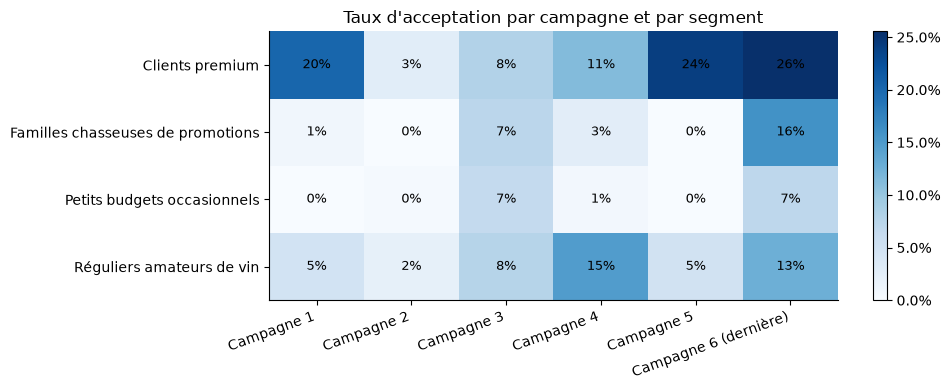

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
image = ax.imshow(par_segment.values, cmap="Blues", aspect="auto")   # carte de chaleur : plus c'est foncé, plus le taux est élevé
ax.set_xticks(range(len(par_segment.columns)), par_segment.columns, rotation=20, ha="right")
ax.set_yticks(range(len(par_segment.index)), par_segment.index)
for i in range(par_segment.shape[0]):                                # écrit la valeur dans chaque case
    for j in range(par_segment.shape[1]):
        ax.text(j, i, f"{par_segment.iat[i, j]:.0%}", ha="center", va="center", fontsize=9)
ax.set_title("Taux d'acceptation par campagne et par segment")
plt.colorbar(image, ax=ax, format=plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig("../outputs/figures/05_campagnes_segments.png", dpi=150)
plt.show()

> **Constat :** aucune campagne n'a été rentable. Les cinq premières ont été acceptées par 1 à 8 % des clients, la dernière par 15 %, alors qu'il faudrait dépasser 27 % pour couvrir les coûts. Envoyée à toute la base, chaque campagne a perdu entre 3 000 et 6 400 u.m. Les clients premium sont de loin les plus réceptifs (jusqu'à 24 % à la campagne 5 et 26 % à la dernière) ; les petits budgets occasionnels n'ont presque jamais dépassé 7 %. Les réguliers amateurs de vin ont surtout réagi à la campagne 4 (15 %), et les familles chasseuses de promotions à la dernière (16 %), ce qui suggère que le contenu de l'offre compte autant que le ciblage.

## 3. Score « hors échantillon »

Le score du notebook 04 a été appliqué à toute la base, y compris aux clients sur lesquels le modèle a appris : sur ces clients, il est un peu trop optimiste. Pour une simulation honnête, on recalcule le score par **validation croisée** : la base est découpée en 5 parts, et chaque part est scorée par un modèle entraîné sur les 4 autres. Chaque client reçoit ainsi un score calculé sans l'avoir vu.

In [6]:
df["En_couple"] = (df["Situation"] == "En couple").astype(int)      # mêmes variables que dans le notebook 04
df["Depense_log"] = np.log1p(df["Depense_totale"])
variables = ["Recency", "Nb_campagnes_acceptees", "Income", "Depense_log", "Achats_total", "Nb_enfants",
             "En_couple", "Part_promo", "Part_web", "Part_catalogue", "NumWebVisitsMonth", "Anciennete_mois", "Age"]

modele = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # 5 parts avec le même taux de répondants
df["Score_hors_echantillon"] = cross_val_predict(modele, df[variables], df["Response"],
                                                 cv=plis, method="predict_proba")[:, 1]   # probabilité de réponse
df = df.sort_values("Score_hors_echantillon", ascending=False).reset_index(drop=True)   # du mieux au moins bien scoré
df["Decile_ciblage"] = pd.qcut(df.index, 10, labels=range(1, 11)).astype(int)            # décile 1 = les 10 % les mieux scorés

## 4. Simulation : toute la base contre ciblage par décile

Pour chaque scénario, on contacte les clients des premiers déciles et on calcule :
- **coût** = nombre de contacts × 3 ;
- **revenu** = nombre de répondants × 11 ;
- **résultat** = revenu − coût ;
- **ROI** = résultat / coût.

In [7]:
def simuler(donnees, cout=COUT_CONTACT, revenu=REVENU_REPONSE):    # calcule les indicateurs d'un ciblage
    contacts = len(donnees)                                        # nombre de clients contactés
    repondants = donnees["Response"].sum()                         # nombre de répondants parmi eux
    cout_total = contacts * cout
    revenu_total = repondants * revenu
    return pd.Series({"contacts": contacts,
                      "repondants": repondants,
                      "taux_reponse": repondants / contacts,
                      "cout": cout_total,
                      "revenu": revenu_total,
                      "resultat": revenu_total - cout_total,
                      "roi": (revenu_total - cout_total) / cout_total})

scenarios = pd.DataFrame({f"Top {d * 10} %": simuler(df[df["Decile_ciblage"] <= d])   # un scénario par décile cumulé
                          for d in range(1, 11)}).T
scenarios = scenarios.rename(index={"Top 100 %": "Toute la base"})
scenarios.round(2)

,contacts,repondants,taux_reponse,cout,revenu,resultat,roi
Top 10 %,223.0,159.0,0.71,669.0,1749.0,1080.0,1.61
Top 20 %,446.0,231.0,0.52,1338.0,2541.0,1203.0,0.90
Top 30 %,669.0,277.0,0.41,2007.0,3047.0,1040.0,0.52
Top 40 %,891.0,301.0,0.34,2673.0,3311.0,638.0,0.24
Top 50 %,1114.0,315.0,0.28,3342.0,3465.0,123.0,0.04
Top 60 %,1337.0,320.0,0.24,4011.0,3520.0,-491.0,-0.12
Top 70 %,1559.0,327.0,0.21,4677.0,3597.0,-1080.0,-0.23
Top 80 %,1782.0,332.0,0.19,5346.0,3652.0,-1694.0,-0.32
Top 90 %,2005.0,332.0,0.17,6015.0,3652.0,-2363.0,-0.39
Toute la base,2228.0,332.0,0.15,6684.0,3652.0,-3032.0,-0.45


In [8]:
meilleur = scenarios["resultat"].idxmax()                          # scénario au meilleur résultat
base = scenarios.loc["Toute la base"]
print(f"Envoi à toute la base : résultat de {base['resultat']:,.0f} u.m. (ROI {base['roi']:.0%})")
print(f"Meilleur scénario     : {meilleur}, résultat de {scenarios.loc[meilleur, 'resultat']:,.0f} u.m. "
      f"(ROI {scenarios.loc[meilleur, 'roi']:.0%}), "
      f"avec {scenarios.loc[meilleur, 'repondants'] / base['repondants']:.0%} des répondants")

Envoi à toute la base : résultat de -3,032 u.m. (ROI -45%)
Meilleur scénario     : Top 20 %, résultat de 1,203 u.m. (ROI 90%), avec 70% des répondants


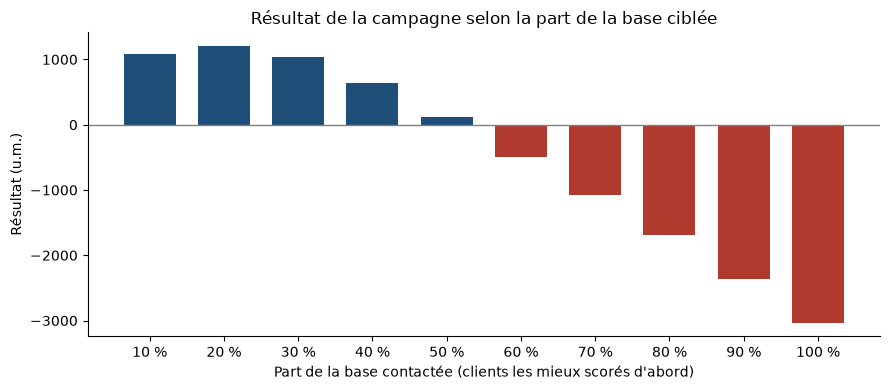

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
x = range(10, 101, 10)                                             # part de la base contactée, de 10 à 100 %
couleurs = [COULEUR if r > 0 else "#B03A2E" for r in scenarios["resultat"]]   # bleu si bénéfice, rouge si perte
ax.bar(x, scenarios["resultat"], width=7, color=couleurs)
ax.axhline(0, color="grey", linewidth=1)
ax.set_xticks(list(x), [f"{v} %" for v in x])
ax.set_xlabel("Part de la base contactée (clients les mieux scorés d'abord)")
ax.set_ylabel("Résultat (u.m.)")
ax.set_title("Résultat de la campagne selon la part de la base ciblée")
plt.tight_layout()
plt.savefig("../outputs/figures/05_resultat_ciblage.png", dpi=150)
plt.show()

> **Constat :** un envoi à toute la base fait perdre 3 032 u.m. (ROI de −45 %). En ne contactant que les 20 % de clients les mieux scorés, la campagne rapporte 1 203 u.m. (ROI de +90 %) : elle touche 70 % des répondants, pour 80 % de contacts en moins. L'écart entre les deux scénarios atteint 4 235 u.m. Au-delà de 50 % de la base contactée, la campagne redevient déficitaire.

## 5. Ciblage par segment

Alternative plus simple à mettre en œuvre : ne contacter que certains segments, sans score.

In [10]:
par_seg = pd.DataFrame({seg: simuler(df[df["Nom_segment"] == seg])   # un scénario par segment
                        for seg in df["Nom_segment"].unique()}).T
par_seg.sort_values("resultat", ascending=False).round(2)

,contacts,repondants,taux_reponse,cout,revenu,resultat,roi
Clients premium,544.0,139.0,0.26,1632.0,1529.0,-103.0,-0.06
Familles chasseuses de promotions,459.0,73.0,0.16,1377.0,803.0,-574.0,-0.42
Réguliers amateurs de vin,612.0,77.0,0.13,1836.0,847.0,-989.0,-0.54
Petits budgets occasionnels,613.0,43.0,0.07,1839.0,473.0,-1366.0,-0.74


> **Constat :** aucun segment n'est rentable s'il est contacté en entier. Même les clients premium, les plus réceptifs (26 %), restent sous le seuil de 27 % et font perdre 103 u.m. Le ciblage par segment ne suffit donc pas : c'est le score individuel qui permet de sélectionner les bons clients à l'intérieur de chaque segment.

## 6. Analyse de sensibilité

Les hypothèses de coût et de revenu sont simplifiées. On vérifie que la conclusion tient si elles changent.

In [11]:
resultats = []
for cout in [2, 3, 5]:                                              # trois hypothèses de coût par contact
    for revenu in [8, 11, 15]:                                      # trois hypothèses de revenu par réponse
        sc = pd.DataFrame({d: simuler(df[df["Decile_ciblage"] <= d], cout, revenu) for d in range(1, 11)}).T
        d_opt = sc["resultat"].idxmax()                             # nombre de déciles optimal
        resultats.append({"cout_contact": cout, "revenu_reponse": revenu,
                          "part_ciblee_optimale": f"{d_opt * 10} %",
                          "resultat_optimal": sc.loc[d_opt, "resultat"],
                          "resultat_toute_base": sc.loc[10, "resultat"]})
pd.DataFrame(resultats).round(0)

,cout_contact,revenu_reponse,part_ciblee_optimale,resultat_optimal,resultat_toute_base
0,2,8,20 %,956.0,-1800.0
1,2,11,30 %,1709.0,-804.0
2,2,15,30 %,2817.0,524.0
3,3,8,10 %,603.0,-4028.0
4,3,11,20 %,1203.0,-3032.0
5,3,15,30 %,2148.0,-1704.0
6,5,8,10 %,157.0,-8484.0
7,5,11,10 %,634.0,-7488.0
8,5,15,10 %,1270.0,-6160.0


> **Constat :** la conclusion tient dans les neuf combinaisons testées. Le ciblage par le score est toujours rentable, avec un résultat compris entre 157 et 2 817 u.m. La part optimale à cibler varie de 10 % (contacts chers ou réponses peu rémunératrices) à 30 % (contacts peu chers ou réponses très rémunératrices). L'envoi à toute la base n'est rentable que dans un seul cas sur neuf, et il rapporte alors moins que le ciblage (524 u.m. contre 2 817).

## 7. Export pour le dashboard

In [12]:
colonnes = ["ID", "Nom_segment", "Age", "Income", "Situation", "Education_fr", "Nb_enfants",
            "Depense_totale", "Achats_total", "Part_promo", "Part_web", "Part_catalogue", "Part_magasin",
            "Recency", "Nb_campagnes_acceptees", "Response", "Score_hors_echantillon", "Decile_ciblage"]
df[colonnes].to_csv("../outputs/dashboard_clients.csv", index=False)                  # une ligne par client
scenarios.reset_index(names="scenario").to_csv("../outputs/dashboard_scenarios.csv", index=False)   # une ligne par scénario
print("Exports terminés : outputs/dashboard_clients.csv et outputs/dashboard_scenarios.csv")

Exports terminés : outputs/dashboard_clients.csv et outputs/dashboard_scenarios.csv


## Synthèse et recommandations

Les campagnes envoyées à toute la base sont structurellement déficitaires : avec un coût de 3 u.m. par contact et un revenu de 11 u.m. par réponse, il faudrait plus de 27 % de réponse pour être rentable, alors que la meilleure campagne atteint 15 %.

1. **Arrêter les envois à toute la base.** Chaque campagne de ce type a perdu entre 3 000 et 6 400 u.m.
2. **Cibler les 20 % de clients les mieux scorés.** La campagne passe d'une perte de 3 032 u.m. à un gain de 1 203 u.m., avec 70 % des répondants conservés et 80 % de contacts en moins. Ce choix reste rentable quelles que soient les hypothèses de coût et de revenu testées.
3. **Adapter le message au segment.** Le score décide qui contacter, la segmentation guide ce que l'on dit : offres exclusives et catalogue pour les clients premium, sélections de vins pour les réguliers amateurs de vin, promotions familiales pour les familles chasseuses de promotions. Les petits budgets occasionnels relèvent de canaux à coût quasi nul (e-mail, site).